# Phase 2: Baseline Model Training & Comparative Evaluation
## Configuration: Authentic Multi-Class CAD Severity Without SMOTE (5-Class)
### Evaluated Architectures: Logistic Regression, KNN, SVM, Random Forest, Lightweight Neural Network

### Clinical & Methodological Scope:
Authentic 5-class CAD severity preserving genuine clinical disease prevalence without synthetic data generation.

### Baseline Architecture Portfolio:
1. **Multinomial / Binary Logistic Regression**: Standard linear probability baseline.
2. **K-Nearest Neighbors (KNN)**: Non-parametric distance-based instance classifier ($k=5$).
3. **Support Vector Classifier (SVM)**: Maximum-margin hyperplane with non-linear RBF kernel.
4. **Random Forest Classifier**: Ensemble of 100 decorrelated decision trees.
5. **Lightweight Neural Network (MLP)**: Feedforward architecture (64 -> 32 neurons) with early stopping.

### Zero-Leakage Guarantee:
All models are trained exclusively on `X_train` (242 samples) and evaluated on the completely untouched holdout test split ($N=61$).

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve, auc
)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("[OK] Baseline modeling environment and specialized architectures loaded successfully.")

[OK] Baseline modeling environment and specialized architectures loaded successfully.


In [2]:
candidates = [
    os.path.join('..', 'datasets', 'heart+disease', 'processed.cleveland.data'),
    os.path.join('datasets', 'heart+disease', 'processed.cleveland.data'),
    'processed.cleveland.data'
]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'processed.cleveland.data'.")

COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df_raw = pd.read_csv(data_path, names=COLUMNS, na_values='?')

df_raw['target_processed'] = df_raw['target'].astype(int)
class_names = ['Class 0 (None)', 'Class 1 (Mild)', 'Class 2 (Mod)', 'Class 3 (Sev)', 'Class 4 (Crit)']
classes_list = [0, 1, 2, 3, 4]

# Train-Test Split
X = df_raw.drop(columns=['target', 'target_processed']).copy()
y = df_raw['target_processed'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Imputation fit strictly on X_train
ca_median = X_train['ca'].median()
thal_mode = X_train['thal'].mode()[0]
X_train['ca'] = X_train['ca'].fillna(ca_median)
X_test['ca'] = X_test['ca'].fillna(ca_median)
X_train['thal'] = X_train['thal'].fillna(thal_mode)
X_test['thal'] = X_test['thal'].fillna(thal_mode)

# One-Hot Encoding
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
X_train_ohe = pd.get_dummies(X_train, columns=nominal_cols, drop_first=False)
X_test_ohe = pd.get_dummies(X_test, columns=nominal_cols, drop_first=False)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

# MinMax Scaling
cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
scaler = MinMaxScaler()
X_train_scaled = X_train_ohe.copy()
X_test_scaled = X_test_ohe.copy()
X_train_scaled[cont_cols] = scaler.fit_transform(X_train_ohe[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test_ohe[cont_cols])

X_train_final, y_train_final = X_train_scaled, y_train
print(f"[OK] Training fold prepared authentically: {len(y_train_final)} instances.")

print(f"[OK] Holdout test set: {len(y_test)} instances.")

[OK] Training fold prepared authentically: 242 instances.
[OK] Holdout test set: 61 instances.


### 1. Training the 5 Baseline Architectures
We initialize and train all five candidate architectures using default configurations.

In [3]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Neural Network (LNN)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
}

y_test_bin = label_binarize(y_test, classes=classes_list)

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_final, y_train_final)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    auc_score = roc_auc_score(y_test_bin, y_prob, multi_class='ovr', average='macro')
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Weighted)': prec,
        'Recall (Weighted)': rec,
        'F1-Score (Weighted)': f1,
        'ROC-AUC (Macro OVR)': auc_score
    })

df_results = pd.DataFrame(results)
print("=== BASELINE EVALUATION RESULTS ===")
print(df_results.to_string(index=False))

=== BASELINE EVALUATION RESULTS ===
                 Model  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-Score (Weighted)  ROC-AUC (Macro OVR)
   Logistic Regression  0.590164              0.524180           0.590164             0.550837             0.817357
   K-Nearest Neighbors  0.590164              0.528866           0.590164             0.550601             0.633693
Support Vector Machine  0.606557              0.541743           0.606557             0.565064             0.794078
         Random Forest  0.540984              0.445466           0.540984             0.487683             0.771493
  Neural Network (LNN)  0.524590              0.518033           0.524590             0.519756             0.747545


### 2. Detailed Per-Model Classification Reports

In [4]:
for name, pred in predictions.items():
    print(f"\n=======================================================")
    print(f"CLASSIFICATION REPORT: {name}")
    print(f"=======================================================")
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))


CLASSIFICATION REPORT: Logistic Regression
                precision    recall  f1-score   support

Class 0 (None)       0.78      0.94      0.85        33
Class 1 (Mild)       0.38      0.27      0.32        11
 Class 2 (Mod)       0.12      0.14      0.13         7
 Class 3 (Sev)       0.20      0.14      0.17         7
Class 4 (Crit)       0.00      0.00      0.00         3

      accuracy                           0.59        61
     macro avg       0.29      0.30      0.29        61
  weighted avg       0.52      0.59      0.55        61


CLASSIFICATION REPORT: K-Nearest Neighbors
                precision    recall  f1-score   support

Class 0 (None)       0.77      0.91      0.83        33
Class 1 (Mild)       0.29      0.36      0.32        11
 Class 2 (Mod)       0.33      0.14      0.20         7
 Class 3 (Sev)       0.20      0.14      0.17         7
Class 4 (Crit)       0.00      0.00      0.00         3

      accuracy                           0.59        61
     macro 

### 3. Visual Diagnostic Suite: Confusion Matrices & ROC Curves

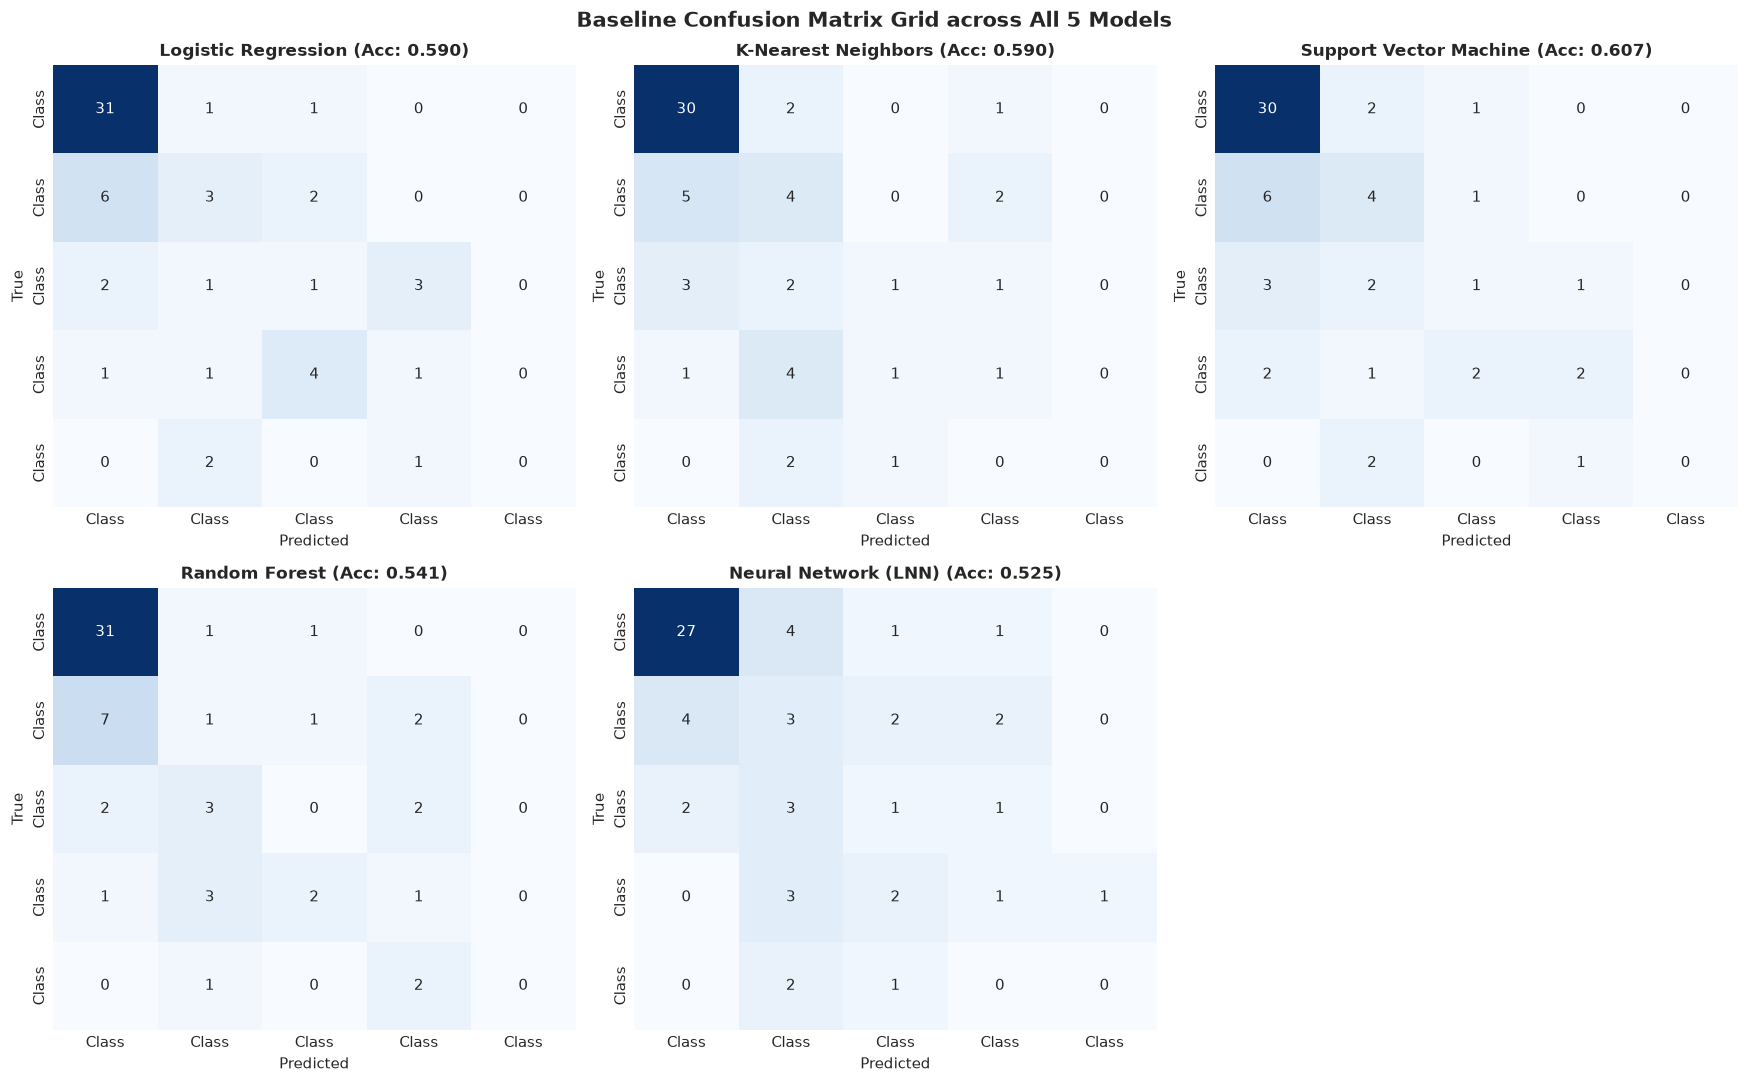

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=[c.split(' ')[0] for c in class_names],
                yticklabels=[c.split(' ')[0] for c in class_names])
    acc_val = df_results.loc[df_results['Model'] == name, 'Accuracy'].values[0]
    axes[idx].set_title(f'{name} (Acc: {acc_val:.3f})', fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('True')

# Hide 6th empty subplot
axes[5].axis('off')

plt.suptitle('Baseline Confusion Matrix Grid across All 5 Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

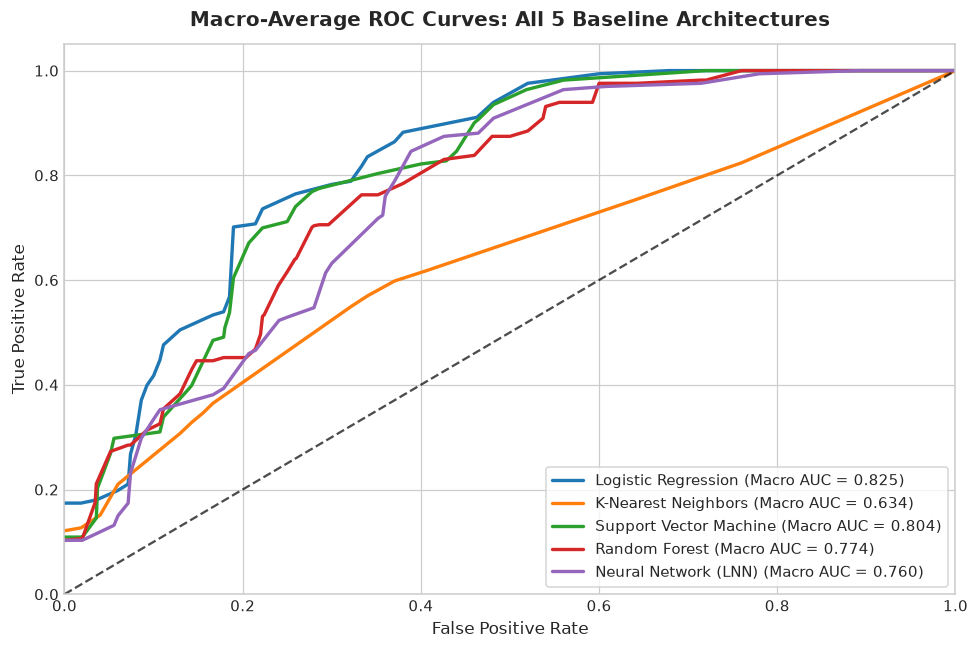

In [6]:
plt.figure(figsize=(9, 6))

for name, prob in probabilities.items():
    all_fpr = np.unique(np.concatenate([roc_curve(y_test_bin[:, i], prob[:, i])[0] for i in range(len(classes_list))]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(len(classes_list)):
        fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], prob[:, i])
        mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
    mean_tpr /= len(classes_list)
    macro_auc = auc(all_fpr, mean_tpr)
    plt.plot(all_fpr, mean_tpr, lw=2.2, label=f'{name} (Macro AUC = {macro_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Macro-Average ROC Curves: All 5 Baseline Architectures', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

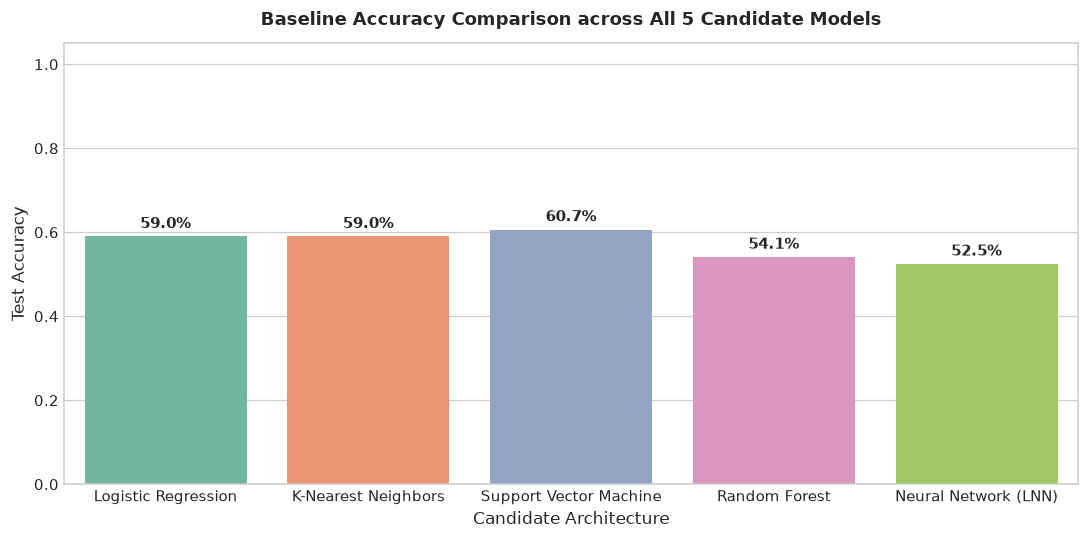

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='Accuracy', data=df_results, palette='Set2')
plt.title('Baseline Accuracy Comparison across All 5 Candidate Models', fontsize=12, fontweight='bold', pad=12)
plt.ylim(0, 1.05)
plt.ylabel('Test Accuracy', fontsize=11)
plt.xlabel('Candidate Architecture', fontsize=11)
for idx, row in df_results.iterrows():
    plt.text(idx, row['Accuracy'] + 0.02, f"{row['Accuracy']*100:.1f}%", ha='center', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.show()

### 4. Baseline Modeling Insights & Transition to Phase 3
- The baseline models establish the initial performance floor.
- In `hyperparameter_tuning.ipynb`, we systematically optimize all 5 models via 5-fold cross-validation across comprehensive hyperparameter search spaces.